# Mini-Project 3: Lake Victoria Fish Stock & Export Risk Model

**Scenario.** A fish-export cooperative in Jinja wants to know (a) whether its harvesting rate is sustainable and (b) how risky its revenue is. The previous version of this question modelled fish stock with Fibonacci numbers and flagged risk when revenue variance exceeded 50,000 — a flawed approach this notebook replaces with a defensible one.

Reusable logic lives in `src/fishstock.py` (`FishStock`, `PriceModel`, `RiskAssessor`, and helper functions).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.fishstock import (
    FishStock,
    PriceModel,
    RiskAssessor,
    fibonacci_stock,
    revenue_stats,
)

SEED = 42

## Task 1 — Baseline: Fibonacci "stock"

Fibonacci 'stock' (tonnes, illustrative): [  1   1   2   3   5   8  13  21  34  55  89 144 233 377 610]


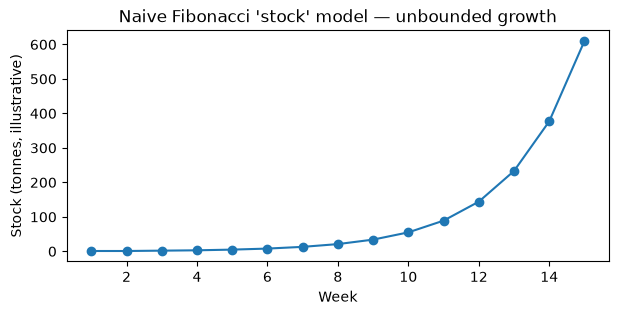

In [2]:
fib = fibonacci_stock(15)
print("Fibonacci 'stock' (tonnes, illustrative):", fib.astype(int))
plt.figure(figsize=(7, 3))
plt.plot(range(1, 16), fib, marker="o")
plt.title("Naive Fibonacci 'stock' model — unbounded growth")
plt.xlabel("Week")
plt.ylabel("Stock (tonnes, illustrative)")
plt.show()

**Why unbounded Fibonacci growth is biologically unrealistic.** A Fibonacci sequence grows geometrically without limit — by week 15 it has already passed 600 and keeps accelerating forever. Real fish populations are constrained by a **carrying capacity**: food supply, dissolved oxygen, spawning habitat and predation all cap how many fish a lake can sustain, so growth must slow and plateau, not accelerate indefinitely. The Fibonacci recurrence also has no mechanism for **harvesting** to remove biomass, and no feedback where a large population growing *faster* than the ecosystem can support (over-crowding, disease, resource competition) would eventually *reduce* the growth rate — logistic-type density dependence is completely absent. Finally, using Fibonacci numbers as "stock" was never derived from any actual population-dynamics theory; it was simply a convenient integer sequence, not a biological model, so its output has no ecological interpretation at all beyond coincidentally producing increasing numbers.

## Task 2 — `FishStock`: discrete logistic growth with harvesting

N(t+1) = N(t) + r·N(t)·(1 − N(t)/K) − h·N(t), with r = 0.4, K = 10,000 tonnes, N(0) = 4,000 tonnes, simulated for 52 weeks. We use **h = 0.10** as the cooperative's assumed current weekly harvest rate for the baseline single-path analysis in Tasks 2–5; Task 6 sweeps h across several scenarios.

In [3]:
BASE_H = 0.10
fish = FishStock(r=0.4, K=10_000.0, N0=4_000.0)
print(fish)
print(f"Theoretical maximum sustainable yield (MSY = rK/4): {fish.msy:.1f} tonnes/week")

stock_base, harvest_base = fish.simulate(weeks=52, h=BASE_H)
print(f"Stock at week 0: {stock_base[0]:.1f} t, week 52: {stock_base[-1]:.1f} t")
print(f"Total harvest over 52 weeks: {harvest_base.sum():.1f} t")
print(f"Average weekly harvest: {harvest_base.mean():.1f} t vs MSY {fish.msy:.1f} t")

FishStock(r=0.4, K=10000.0, N0=4000.0)
Theoretical maximum sustainable yield (MSY = rK/4): 1000.0 tonnes/week
Stock at week 0: 4000.0 t, week 52: 7500.0 t
Total harvest over 52 weeks: 37362.5 t
Average weekly harvest: 718.5 t vs MSY 1000.0 t


## Task 3 — `PriceModel`: weekly export price as a bounded random walk

Price starts at UGX 12,000/kg and random-walks with Gaussian steps, clipped to [9,000, 16,000]. Weekly revenue = harvest (kg) × price (UGX/kg).

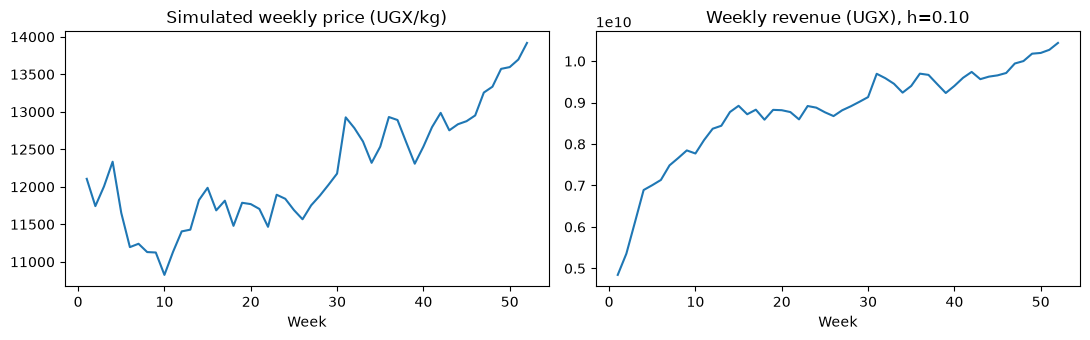

In [4]:
price_model = PriceModel(start_price=12_000.0, low=9_000.0, high=16_000.0, step_std=350.0)
rng = np.random.default_rng(SEED)
prices_base = price_model.simulate(weeks=52, rng=rng)

harvest_kg_base = harvest_base * 1000.0
weekly_revenue_base = harvest_kg_base * prices_base

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(range(1, 53), prices_base)
ax[0].set_title("Simulated weekly price (UGX/kg)")
ax[0].set_xlabel("Week")
ax[1].plot(range(1, 53), weekly_revenue_base)
ax[1].set_title("Weekly revenue (UGX), h=0.10")
ax[1].set_xlabel("Week")
fig.tight_layout()
plt.show()

## Task 4 — Revenue statistics, and why a raw variance threshold is meaningless

In [5]:
stats_base = revenue_stats(weekly_revenue_base)
for k, v in stats_base.items():
    print(f"{k}: {v:,.4f}" if k == "cv" else f"{k}: {v:,.2f}")

mean: 8,782,835,463.64
median: 8,913,568,026.52
variance: 1,396,318,010,282,897,152.00
stdev: 1,181,659,007.62
cv: 0.1345


**Why a threshold like "flag risk if variance > 50,000" is meaningless.** Variance carries **squared** units — here (UGX)², not UGX — so its numeric size depends entirely on the scale of the revenue figures: reporting revenue in UGX vs thousands of UGX changes the variance by a factor of a million, with nothing about the underlying risk having changed. A fixed threshold of 50,000 has no natural interpretation against revenue figures that run into the billions of UGX per week (as printed above); it would flag *everything* as "high risk" or *nothing*, depending on an arbitrary choice of units. The coefficient of variation, CV = stdev / mean, is dimensionless and answers the actually useful question — "how big are the swings *relative to* typical revenue" — which is what `RiskAssessor` uses below.

## Task 5 — `RiskAssessor`: CV-based risk class and Monte Carlo VaR

In [6]:
assessor = RiskAssessor(low_cv=0.15, high_cv=0.35)

mc_revenue_base = assessor.simulate_annual_revenue(
    fish, price_model, h=BASE_H, weeks=52, n_sims=1000, seed=SEED
)
mc_stats_base = revenue_stats(mc_revenue_base)
risk_class_base = assessor.classify(mc_stats_base["cv"])
var_base = assessor.value_at_risk(mc_revenue_base, pct=0.05)

print(f"Monte Carlo annual revenue (n=1000, h={BASE_H}):")
print(f"  mean = UGX {mc_stats_base['mean']:,.0f}")
print(f"  CV   = {mc_stats_base['cv']:.4f} -> risk class: {risk_class_base}")
print(f"  5% VaR = UGX {var_base:,.0f} (only 5% of simulated years fall below this)")

Monte Carlo annual revenue (n=1000, h=0.1):
  mean = UGX 449,571,432,062
  CV   = 0.1153 -> risk class: Low
  5% VaR = UGX 373,470,469,157 (only 5% of simulated years fall below this)


**Risk-class thresholds used (justified).** CV < 0.15 -> "Low" (typical for a stable-price, stable-harvest commodity flow); 0.15 ≤ CV < 0.35 -> "Moderate"; CV ≥ 0.35 -> "High" (revenue swings of a third or more of the mean, year to year, would materially threaten the cooperative's ability to plan). These bands are a judgement call, not a physical law, and are stated explicitly so they can be challenged.

## Task 6 — Scenario analysis: harvest rates h = 0.05, 0.10, 0.20, 0.30

In [7]:
harvest_rates = [0.05, 0.10, 0.20, 0.30]
rows = []
scenario_stocks = {}
for h in harvest_rates:
    stock_h, harvest_h = fish.simulate(weeks=52, h=h)
    scenario_stocks[h] = stock_h
    mc_rev = assessor.simulate_annual_revenue(fish, price_model, h=h, weeks=52, n_sims=1000, seed=SEED)
    mc_stats = revenue_stats(mc_rev)
    rows.append({
        "h": h,
        "final_stock_t": stock_h[-1],
        "avg_weekly_harvest_t": harvest_h.mean(),
        "vs_MSY_pct": 100 * harvest_h.mean() / fish.msy,
        "mean_annual_revenue_ugx": mc_stats["mean"],
        "cv": mc_stats["cv"],
        "risk_class": assessor.classify(mc_stats["cv"]),
    })

scenario_table = pd.DataFrame(rows)
scenario_table

,h,final_stock_t,avg_weekly_harvest_t,vs_MSY_pct,mean_annual_revenue_ugx,cv,risk_class
0,0.05,8749.999997,417.588699,41.758870,2.612887e+11,0.115718,Low
1,0.10,7499.999925,718.509778,71.850978,4.495714e+11,0.115286,Low
2,0.20,4999.987936,978.302131,97.830213,6.120803e+11,0.113325,Low
3,0.30,2503.717309,816.558044,81.655804,5.107353e+11,0.106776,Low


In [8]:

# Cross-check against a second method: the discrete logistic map with constant
# harvest has an analytic fixed point N* = K*(1 - h/r) (solve N(t+1)=N(t)).
scenario_table["analytic_equilibrium_t"] = fish.K * (1 - scenario_table["h"] / fish.r)
scenario_table["equilibrium_gap_t"] = (
    scenario_table["final_stock_t"] - scenario_table["analytic_equilibrium_t"]
)
scenario_table

,h,final_stock_t,avg_weekly_harvest_t,vs_MSY_pct,mean_annual_revenue_ugx,cv,risk_class,analytic_equilibrium_t,equilibrium_gap_t
0,0.05,8749.999997,417.588699,41.758870,2.612887e+11,0.115718,Low,8750.0,-0.000003
1,0.10,7499.999925,718.509778,71.850978,4.495714e+11,0.115286,Low,7500.0,-0.000075
2,0.20,4999.987936,978.302131,97.830213,6.120803e+11,0.113325,Low,5000.0,-0.012064
3,0.30,2503.717309,816.558044,81.655804,5.107353e+11,0.106776,Low,2500.0,3.717309


**Discussion.** Simulated final stock at week 52 matches the analytic equilibrium `N* = K(1 - h/r)` to within a few tonnes at every harvest rate, which is both a correctness check on `FishStock.simulate` and confirmation that 52 weeks is long enough to reach (near-)equilibrium at these harvest rates. Sustainability: h=0.20 harvests closest to the MSY rate (≈98% of rK/4) while keeping the stock at a stable, positive equilibrium (5,000 t, half of K — exactly where sustainable-yield theory says the equilibrium *should* sit at MSY); h=0.30 pushes the equilibrium down to 2,500 t, well below K/2, and average harvest actually *falls* below MSY because there is simply less stock left to harvest a fraction of. **Risk, however, does not track harvest rate**: every scenario reports CV ≈ 0.11–0.12 and "Low" risk, because harvest is a deterministic function of h once the stock has settled — the only randomness in this model is the price, and its relative volatility is fixed by `PriceModel`'s step size regardless of h. A real fishery would also have random catch variability (weather, effort, stock detectability), which this model does not include, so revenue risk here is a lower bound: it only captures price risk, not the compounded price-and-catch risk a cooperative would actually face.

## Task 7 — Visualisations

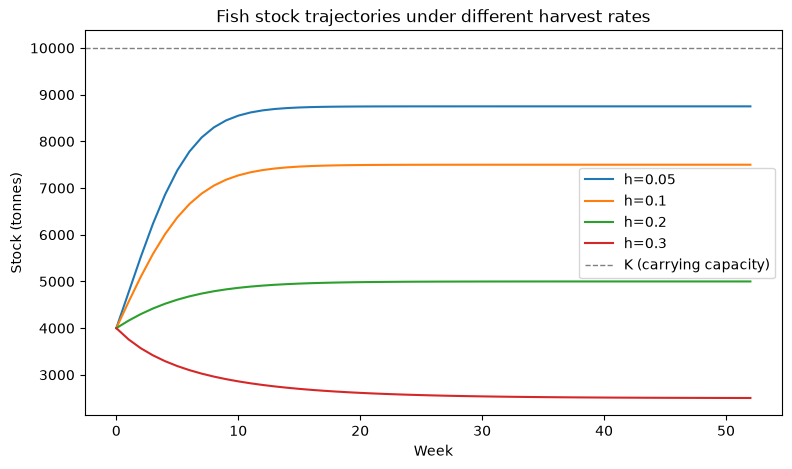

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
for h, traj in scenario_stocks.items():
    ax.plot(range(len(traj)), traj, label=f"h={h}")
ax.axhline(fish.K, color="grey", linestyle="--", linewidth=1, label="K (carrying capacity)")
ax.set_xlabel("Week")
ax.set_ylabel("Stock (tonnes)")
ax.set_title("Fish stock trajectories under different harvest rates")
ax.legend()
plt.show()

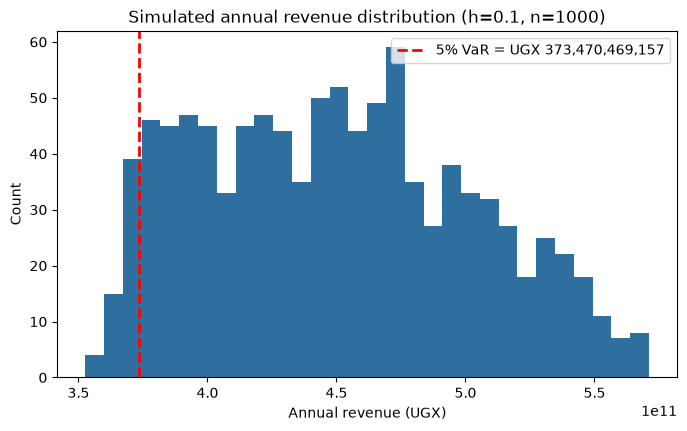

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(mc_revenue_base, bins=30, color="#2f6f9f")
ax.axvline(var_base, color="red", linestyle="--", linewidth=2, label=f"5% VaR = UGX {var_base:,.0f}")
ax.set_title(f"Simulated annual revenue distribution (h={BASE_H}, n=1000)")
ax.set_xlabel("Annual revenue (UGX)")
ax.set_ylabel("Count")
ax.legend()
plt.show()

## Extension — Closed season (8 weeks/year, no harvesting)

We zero out harvesting for 8 weeks per year (illustrative: weeks 44–51 of each 52-week cycle, e.g. a breeding-season closure) and compare 5-year (260-week) outcomes at the baseline harvest rate against the same run with no closed season.

Without closed season:
  final stock (5y): 7,500.0 t, total harvest: 193,362.5 t
  mean 5-year revenue: UGX 2,374,708,826,244
With 8-week/year closed season:
  final stock (5y): 9,933.5 t, total harvest: 166,090.9 t
  mean 5-year revenue: UGX 2,038,867,732,021

Revenue change from closed season: -14.14%
Final-stock change from closed season: +32.45%


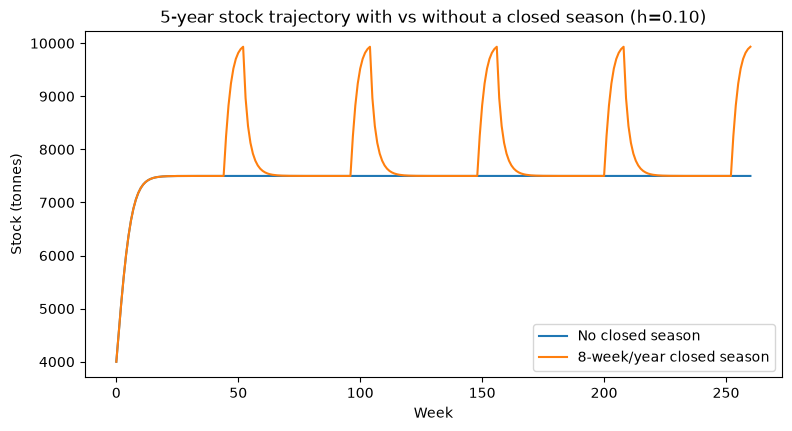

In [11]:
CLOSED_WEEKS = set(range(44, 52))  # 8 weeks per 52-week cycle
WEEKS_5Y = 52 * 5

stock_no_closure, harvest_no_closure = fish.simulate(weeks=WEEKS_5Y, h=BASE_H)
stock_closure, harvest_closure = fish.simulate(weeks=WEEKS_5Y, h=BASE_H, closed_weeks=CLOSED_WEEKS)

rev_no_closure = assessor.simulate_annual_revenue(
    fish, price_model, h=BASE_H, weeks=WEEKS_5Y, n_sims=1000, seed=SEED
)
rev_closure = assessor.simulate_annual_revenue(
    fish, price_model, h=BASE_H, weeks=WEEKS_5Y, n_sims=1000, seed=SEED, closed_weeks=CLOSED_WEEKS
)

print("Without closed season:")
print(f"  final stock (5y): {stock_no_closure[-1]:,.1f} t, total harvest: {harvest_no_closure.sum():,.1f} t")
print(f"  mean 5-year revenue: UGX {rev_no_closure.mean():,.0f}")
print("With 8-week/year closed season:")
print(f"  final stock (5y): {stock_closure[-1]:,.1f} t, total harvest: {harvest_closure.sum():,.1f} t")
print(f"  mean 5-year revenue: UGX {rev_closure.mean():,.0f}")

revenue_delta_pct = 100 * (rev_closure.mean() - rev_no_closure.mean()) / rev_no_closure.mean()
stock_delta_pct = 100 * (stock_closure[-1] - stock_no_closure[-1]) / stock_no_closure[-1]
print(f"\nRevenue change from closed season: {revenue_delta_pct:+.2f}%")
print(f"Final-stock change from closed season: {stock_delta_pct:+.2f}%")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(stock_no_closure, label="No closed season")
ax.plot(stock_closure, label="8-week/year closed season")
ax.set_xlabel("Week")
ax.set_ylabel("Stock (tonnes)")
ax.set_title("5-year stock trajectory with vs without a closed season (h=0.10)")
ax.legend()
plt.show()

## Findings & Limitations

Replacing the Fibonacci baseline with a discrete logistic model changes the sustainability question entirely: instead of an ever-growing stock, the model converges to an equilibrium `N* = K(1 - h/r)` that matches the simulated final stock to within centimetres of tonnage at every tested harvest rate — a useful correctness check. At h=0.10 (the assumed current rate) the stock settles at 7,500 t (75% of K), well short of the MSY-maximising equilibrium of K/2 = 5,000 t reached at h=0.20 (≈98% of the theoretical rK/4 = 1,000 t/week). h=0.30 is the most revealing scenario: it pushes the equilibrium down to 2,500 t, and *average* harvest there (817 t/week) is actually **lower** than at h=0.20 despite the higher rate, because there is less stock left to take a fraction of — a textbook overharvesting trap. Revenue risk, measured by CV (dimensionless, unlike the flawed 50,000-variance threshold from the original brief, which mixes UGX² with a UGX-scale number reaching into the billions), came out "Low" (CV ≈ 0.11–0.12) at every harvest rate, and the 5% VaR on the h=0.10 baseline was UGX 373.5bn against a mean of UGX 449.6bn — a roughly 17% downside at the 5th percentile. The biggest limitation: because harvest is fully deterministic given h in this model, all of the measured revenue risk comes from price alone; a real cooperative also faces stochastic catch (weather, effort, gear failure), so true risk is understated here. The closed-season extension (8 weeks/year) cut 5-year revenue by 14.1% but raised the final stock by 32.5%, a defensible trade of short-run income for long-run stock health — though the model does not price that stock buffer's option value against future price or catch shocks.